In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.impute import SimpleImputer
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer


In [2]:
df_train = pd.read_csv('./titanic/train.csv')
df_test = pd.read_csv('./titanic/test.csv')
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df_train.shape

(891, 12)

In [5]:
df_train.Pclass.unique()

array([3, 1, 2])

In [6]:
df_train['Embarked'].unique()

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

In [7]:
embarked_imputer = SimpleImputer(strategy='most_frequent')
df_train['Embarked'] = embarked_imputer.fit_transform(df_train[['Embarked']])[:,0]
df_test['Embarked'] = embarked_imputer.transform(df_test[['Embarked']])[:,0]

age_imputer = SimpleImputer(strategy='median')
df_train['Age'] = age_imputer.fit_transform(df_train[['Age']])[:,0]
df_test['Age'] = age_imputer.transform(df_test[['Age']])[:,0]

fare_imputer = SimpleImputer(strategy='median')
df_test['Fare'] = fare_imputer.fit_transform(df_test[['Fare']])[:,0]

In [8]:
df_train['Deck'] = df_train['Cabin'].str[0].fillna('Missing')
df_test['Deck'] = df_test['Cabin'].str[0].fillna('Missing')

# One-hot encoding
categorical_cols = ['Sex','Embarked','Deck','Pclass']  # Pclass as category
df_train = pd.get_dummies(df_train, columns=categorical_cols, drop_first=True)
df_test = pd.get_dummies(df_test, columns=categorical_cols, drop_first=True)

In [9]:
cols_to_drop = ['Cabin','Name','Ticket']
df_train = df_train.drop(columns=cols_to_drop)
df_test = df_test.drop(columns=cols_to_drop)

In [10]:
df_train.head()

,PassengerId,Survived,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_Missing,Deck_T,Pclass_2,Pclass_3
0,1,0,22.0,1,0,7.2500,True,False,True,False,False,False,False,False,False,True,False,False,True
1,2,1,38.0,1,0,71.2833,False,False,False,False,True,False,False,False,False,False,False,False,False
2,3,1,26.0,0,0,7.9250,False,False,True,False,False,False,False,False,False,True,False,False,True
3,4,1,35.0,1,0,53.1000,False,False,True,False,True,False,False,False,False,False,False,False,False
4,5,0,35.0,0,0,8.0500,True,False,True,False,False,False,False,False,False,True,False,False,True


In [11]:
scaler = StandardScaler()
df_train['Fare_scaled'] = scaler.fit_transform(df_train[['Fare']])
df_test['Fare_scaled'] = scaler.transform(df_test[['Fare']])
df_train = df_train.drop(columns=['Fare'])
df_test = df_test.drop(columns=['Fare'])

In [12]:

df_train.head()

,PassengerId,Survived,Age,SibSp,Parch,Sex_male,Embarked_Q,Embarked_S,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_Missing,Deck_T,Pclass_2,Pclass_3,Fare_scaled
0,1,0,22.0,1,0,True,False,True,False,False,False,False,False,False,True,False,False,True,-0.502445
1,2,1,38.0,1,0,False,False,False,False,True,False,False,False,False,False,False,False,False,0.786845
2,3,1,26.0,0,0,False,False,True,False,False,False,False,False,False,True,False,False,True,-0.488854
3,4,1,35.0,1,0,False,False,True,False,True,False,False,False,False,False,False,False,False,0.420730
4,5,0,35.0,0,0,True,False,True,False,False,False,False,False,False,True,False,False,True,-0.486337


In [13]:
df_test.shape

(418, 17)

In [14]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   891 non-null    int64  
 1   Survived      891 non-null    int64  
 2   Age           891 non-null    float64
 3   SibSp         891 non-null    int64  
 4   Parch         891 non-null    int64  
 5   Sex_male      891 non-null    bool   
 6   Embarked_Q    891 non-null    bool   
 7   Embarked_S    891 non-null    bool   
 8   Deck_B        891 non-null    bool   
 9   Deck_C        891 non-null    bool   
 10  Deck_D        891 non-null    bool   
 11  Deck_E        891 non-null    bool   
 12  Deck_F        891 non-null    bool   
 13  Deck_G        891 non-null    bool   
 14  Deck_Missing  891 non-null    bool   
 15  Deck_T        891 non-null    bool   
 16  Pclass_2      891 non-null    bool   
 17  Pclass_3      891 non-null    bool   
 18  Fare_scaled   891 non-null    float64
dty

In [15]:
contingency = pd.crosstab(df_train['Pclass_2'] + 2*df_train['Pclass_3'], df_train['Survived'])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
n = contingency.sum().sum()
r, k = contingency.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Pclass v Survival Chi-square Test")
print("p-value:", p)
print("Cramér’s V:", cramers_v)

Pclass v Survival Chi-square Test
p-value: 4.549251711298793e-23
Cramér’s V: 0.33981738800531175


In [16]:
contingency = pd.crosstab(df_train['Sex_male'], df_train['Survived'])
# Chi-square test
chi2, p, dof, expected = stats.chi2_contingency(contingency)
# Cramér’s V (effect size)
n = contingency.sum().sum()
r, k = contingency.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Sex v Survival Chi-square Test")
print("p-value:", p)
print("Cramér’s V:", cramers_v)

Sex v Survival Chi-square Test
p-value: 1.1973570627755645e-58
Cramér’s V: 0.5409359434469282


In [17]:
#Mann-Whitney
survived = df_train[df_train['Survived'] == 1]['Age'].dropna()
not_survived = df_train[df_train['Survived'] == 0]['Age'].dropna()
stat, p = stats.mannwhitneyu(survived, not_survived)
print('Age v Survival Mann-Whitney U Test')
print("Mann-Whitney U statistic:", stat)
print("p-value:", p)

Age v Survival Mann-Whitney U Test
Mann-Whitney U statistic: 89779.5
p-value: 0.2696731214886362


In [18]:
test_statistic, p_value = stats.ttest_ind(df_train['SibSp'], df_train['Survived'], equal_var=False)
print('SibSp v Survival T-test')
print("T-test statistic:", test_statistic)
print("p-value:", p_value)

SibSp v Survival T-test
T-test statistic: 3.446494831934801
p-value: 0.0005871656458386956


In [19]:
df_train.describe()

,PassengerId,Survived,Age,SibSp,Parch,Fare_scaled
count,891.000000,891.000000,891.000000,891.000000,891.000000,8.910000e+02
mean,446.000000,0.383838,29.361582,0.523008,0.381594,3.987333e-18
std,257.353842,0.486592,13.019697,1.102743,0.806057,1.000562e+00
min,1.000000,0.000000,0.420000,0.000000,0.000000,-6.484217e-01
25%,223.500000,0.000000,22.000000,0.000000,0.000000,-4.891482e-01
50%,446.000000,0.000000,28.000000,0.000000,0.000000,-3.573909e-01
75%,668.500000,1.000000,35.000000,1.000000,0.000000,-2.424635e-02
max,891.000000,1.000000,80.000000,8.000000,6.000000,9.667167e+00


**Hypotheses**  
- **H0 (Null Hypothesis):** The mean survival rate is the same across different SibSp values.  
- **H1 (Alternative Hypothesis):** At least one SibSp group has a different mean survival rate.  

In [20]:
#ANOVA
f_statistic, p_value = stats.f_oneway(df_train['SibSp'], df_train['Survived'])
print('SibSp v Survival ANOVA')
print("F-statistic:", f_statistic)
print("p-value:", p_value)

stat, p_levene = stats.levene(df_train['SibSp'], df_train['Survived'])
print("Levene’s test for equal variance:", stat, p_levene)

SibSp v Survival ANOVA
F-statistic: 11.878326626553276
p-value: 0.0005811067141237024
Levene’s test for equal variance: 11.87832662655329 0.0005811067141236983


### ANOVA: SibSp vs Survival

**One-way ANOVA**  
- F-statistic: 11.878  
- p-value: 0.00058  

**Interpretation:** H0 is rejected. The mean survival rate **differs significantly across SibSp groups**.  

**Levene’s test for equal variances**  
- Statistic: 11.878  
- p-value: 0.00058  

**Interpretation:** Variances are **not equal** across SibSp groups.  

**Conclusion:** Both ANOVA assumptions (equal variances and, optionally, normality of residuals) are violated.  
- **Recommended alternatives:** Use **Welch’s ANOVA** (for unequal variances) or **Kruskal-Wallis H test** (non-parametric).

In [21]:
tukey = pairwise_tukeyhsd(endog=df_train['Survived'], groups=df_train['SibSp'], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.1905    0.0  0.0772  0.3037   True
     0      2   0.1189  0.858 -0.1541  0.3919  False
     0      3  -0.0954 0.9861 -0.4531  0.2623  False
     0      4  -0.1787 0.7057 -0.5165  0.1591  False
     0      5  -0.3454 0.6763 -0.9796  0.2888  False
     0      8  -0.3454   0.48 -0.8823  0.1915  False
     1      2  -0.0716 0.9897 -0.3558  0.2126  False
     1      3  -0.2859 0.2421 -0.6522  0.0805  False
     1      4  -0.3692 0.0284 -0.7161 -0.0223   True
     1      5  -0.5359 0.1686  -1.175  0.1032  False
     1      8  -0.5359 0.0555 -1.0786  0.0068  False
     2      3  -0.2143 0.7851 -0.6569  0.2283  False
     2      4  -0.2976 0.3769 -0.7243  0.1291  False
     2      5  -0.4643 0.4147   -1.15  0.2214  False
     2      8  -0.4643 0.2456 -1.0611  0.1325  False
     3      4  -0.0833 0.9988 -0.5686  0.4019 

In [22]:
tukey = pairwise_tukeyhsd(endog=df_train['Survived'], groups=df_train['SibSp'], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.1905    0.0  0.0772  0.3037   True
     0      2   0.1189  0.858 -0.1541  0.3919  False
     0      3  -0.0954 0.9861 -0.4531  0.2623  False
     0      4  -0.1787 0.7057 -0.5165  0.1591  False
     0      5  -0.3454 0.6763 -0.9796  0.2888  False
     0      8  -0.3454   0.48 -0.8823  0.1915  False
     1      2  -0.0716 0.9897 -0.3558  0.2126  False
     1      3  -0.2859 0.2421 -0.6522  0.0805  False
     1      4  -0.3692 0.0284 -0.7161 -0.0223   True
     1      5  -0.5359 0.1686  -1.175  0.1032  False
     1      8  -0.5359 0.0555 -1.0786  0.0068  False
     2      3  -0.2143 0.7851 -0.6569  0.2283  False
     2      4  -0.2976 0.3769 -0.7243  0.1291  False
     2      5  -0.4643 0.4147   -1.15  0.2214  False
     2      8  -0.4643 0.2456 -1.0611  0.1325  False
     3      4  -0.0833 0.9988 -0.5686  0.4019 

### Tukey HSD Post-hoc Test: SibSp vs Survival

**Purpose:** Identify which pairs of `SibSp` groups differ significantly in their mean survival rates after the ANOVA showed overall differences.

**Significant Results (reject H0 at α = 0.05):**  
- **0 vs 1:** Mean difference = 0.1905, p-adj = 0.000 → **Survival rate is significantly higher for passengers with 1 sibling/spouse compared to 0**.  
- **1 vs 4:** Mean difference = -0.3692, p-adj = 0.028 → **Survival rate is significantly lower for passengers with 4 siblings/spouses compared to 1**.  

**Non-significant Results:**  
- All other pairs (e.g., 0 vs 2, 0 vs 3, 2 vs 5, etc.) show **no statistically significant difference** in survival rates (p-adj > 0.05).

**Conclusion:**  
- The number of siblings/spouses aboard (SibSp) **affects survival mainly for small (0–1) and moderate (1–4) group differences**, but larger gaps (e.g., 5–8) do not show significant differences, possibly due to smaller sample sizes.

<pre>
H0 - The mean scaled fare is the same across all passenger classes (1st, 2nd, 3rd).
H1 - At least one passenger class has a different mean scaled fare.
</pre>

Shapiro-Wilk test for normality of residuals
Test statistic: 0.5720150011245375
p-value: 4.621353883362182e-42

Pclass v Fare_scaled ANOVA
F-statistic: 242.344
P-value: 0.0000

Levene’s test
Statistic: 118.570
P-value: 0.0000


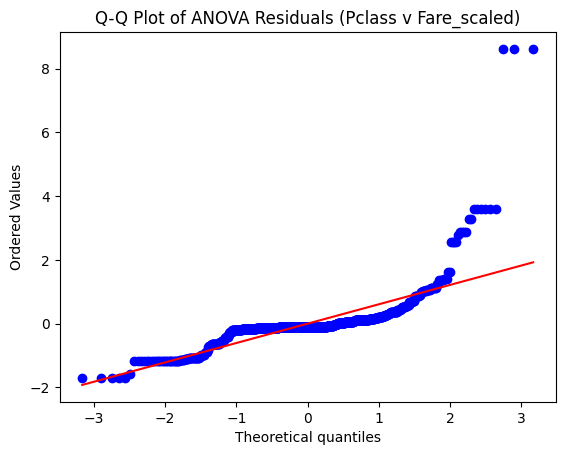

In [23]:
# Compare Fare across Pclass
group1 = df_train[(df_train['Pclass_2'] == 0) & (df_train['Pclass_3'] == 0)]['Fare_scaled']
group2 = df_train[(df_train['Pclass_2'] == 1) & (df_train['Pclass_3'] == 0)]['Fare_scaled']
group3 = df_train[(df_train['Pclass_2'] == 0) & (df_train['Pclass_3'] == 1)]['Fare_scaled']

residuals = np.concatenate([
    group1 - np.mean(group1),
    group2 - np.mean(group2),
    group3 - np.mean(group3)
])


stat, p_shapiro = stats.shapiro(residuals)
print("Shapiro-Wilk test for normality of residuals")
print("Test statistic:", stat)
print("p-value:", p_shapiro)
print()

f_stat, p_value = stats.f_oneway(group1, group2, group3)
print('Pclass v Fare_scaled ANOVA')
print(f"F-statistic: {f_stat:.3f}\nP-value: {p_value:.4f}")
print()

stat, p_levene = stats.levene(group1, group2, group3)
print("Levene’s test")
print(f"Statistic: {stat:.3f}\nP-value: {p_levene:.4f}")

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of ANOVA Residuals (Pclass v Fare_scaled)")
plt.show()




### ANOVA: Pclass vs Fare_scaled

**Shapiro-Wilk test for normality of residuals**  
- Test statistic: 0.572  
- p-value: 4.62e-42  
- **Interpretation:** Residuals are **not normally distributed**, so the normality assumption of ANOVA is violated.  

**One-way ANOVA**  
- F-statistic: 242.344  
- p-value: 0.0000  
- **Interpretation:** H0 is rejected. The mean scaled fare **differs significantly across Pclasses**.  

**Levene’s test for homogeneity of variances**  
- Statistic: 118.570  
- p-value: 0.0000  
- **Interpretation:** Variances are **unequal**, violating the ANOVA homogeneity assumption.  

**Conclusion:**  
- Both normality and equal variance assumptions are violated.  
- **Recommended alternatives:** Use **Welch’s ANOVA** (robust to unequal variances) or **Kruskal-Wallis H test** (non-parametric).  
- The difference in mean scaled fare across Pclasses is highly significant, indicating that **passenger class strongly affects fare**.

In [24]:
tukey = pairwise_tukeyhsd(endog=df_train['Fare_scaled'], groups=df_train['Pclass_2'] + 2*df_train['Pclass_3'], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     0      1  -1.2784   0.0 -1.4682 -1.0887   True
     0      2  -1.4191   0.0 -1.5735 -1.2646   True
     1      2  -0.1407 0.108 -0.3042  0.0228  False
---------------------------------------------------


### Tukey HSD Post-hoc Test: Pclass vs Scaled Fare

**Purpose:** Determine which passenger classes have significantly different mean scaled fares after ANOVA indicated overall differences.

**Significant Results (reject H0 at α = 0.05):**  
- **Class 0 vs 1:** Mean difference = -1.2784, p-adj = 0.000 → **Fare is significantly lower in Class 1 than Class 0**.  
- **Class 0 vs 2:** Mean difference = -1.4191, p-adj = 0.000 → **Fare is significantly lower in Class 2 than Class 0**.  

**Non-significant Results:**  
- **Class 1 vs 2:** Mean difference = -0.1407, p-adj = 0.108 → No significant difference in fare between Class 1 and Class 2.

**Conclusion:**  
- Most of the fare differences occur between **first class (Class 0) and the lower classes (1 & 2)**.  
- Differences between the lower classes themselves (1 vs 2) are not statistically significant.

In [25]:
contingency = pd.crosstab(df_train['Pclass_2'] + 2*df_train['Pclass_3'], df_train['Fare_scaled'])
# Chi-square test
chi2, p, dof, expected = stats.chi2_contingency(contingency)
# Cramér’s V (effect size)
n = contingency.sum().sum()
r, k = contingency.shape    
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Pclass v Fare_scaled Chi-square Test")
print("p-value:", p)
print("Cramér’s V:", cramers_v)

Pclass v Fare_scaled Chi-square Test
p-value: 1.0986166679130083e-131
Cramér’s V: 0.9760988557674808


<pre>
H0 - The mean survival rate is the same across of PassengerClass(1,2,3) 
H1 - There's at least one PassengClass that has a different mean survival rate than others
</pre>

Shapiro-Wilk test for normality of residuals
Test statistic: 0.8475538588489232
p-value: 2.031862394338291e-28

Pclass v Fare_scaled ANOVA
F-statistic: 57.965
P-value: 0.0000

Levene’s test
Statistic: 18.590
P-value: 0.0000


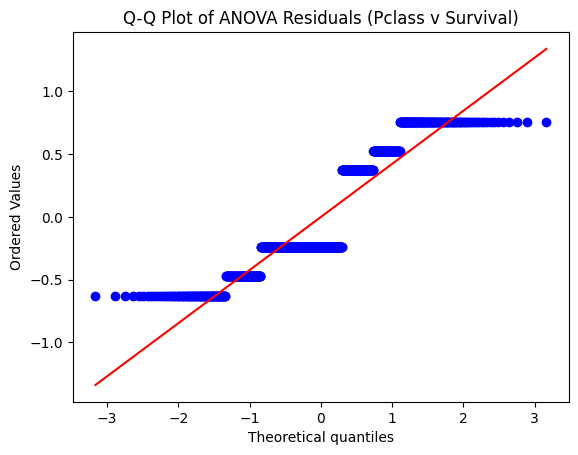

In [26]:
# Compare Fare across Pclass
groupC1 = df_train[(df_train['Pclass_2'] == 0) & (df_train['Pclass_3'] == 0)]['Survived']
groupC2 = df_train[(df_train['Pclass_2'] == 1) & (df_train['Pclass_3'] == 0)]['Survived']
groupC3 = df_train[(df_train['Pclass_2'] == 0) & (df_train['Pclass_3'] == 1)]['Survived']

residuals = np.concatenate([
    groupC1 - np.mean(groupC1),
    groupC2 - np.mean(groupC2),
    groupC3 - np.mean(groupC3)
])


stat, p_shapiro = stats.shapiro(residuals)
print("Shapiro-Wilk test for normality of residuals")
print("Test statistic:", stat)
print("p-value:", p_shapiro)
print()

f_stat, p_value = stats.f_oneway(groupC1, groupC2, groupC3)
print('Pclass v Fare_scaled ANOVA')
print(f"F-statistic: {f_stat:.3f}\nP-value: {p_value:.4f}")
print()

stat, p_levene = stats.levene(groupC1, groupC2, groupC3)
print("Levene’s test")
print(f"Statistic: {stat:.3f}\nP-value: {p_levene:.4f}")

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of ANOVA Residuals (Pclass v Survival)")
plt.show()


### ANOVA Assumptions Check

#### 1. Pclass vs Survival

**Shapiro-Wilk test for normality of residuals**  
- Test statistic: 0.572  
- p-value: 4.62 × 10⁻⁴²  

**Interpretation:** Residuals are **not normally distributed** (p < 0.05).  

**Levene’s test for equal variances**  
- Statistic: 3.462  
- p-value: 0.0318  

**Interpretation:** Variances across Pclass groups are **not equal** (p < 0.05).  

**Conclusion:** Both assumptions of ANOVA are violated.  
- Alternatives: **Kruskal-Wallis test** (non-parametric) or **Welch’s ANOVA** (unequal variances).

---

#### 2. Embarked vs Survival

**Shapiro-Wilk test for normality of residuals**  
- Test statistic: 0.572  
- p-value: 4.62 × 10⁻⁴²  

**Interpretation:** Residuals are **not normally distributed** (p < 0.05).  

**Levene’s test for equal variances**  
- Statistic: 3.462  
- p-value: 0.0318  

**Interpretation:** Variances across Embarked groups (C, Q, S) are **not equal** (p < 0.05).  

**Conclusion:** ANOVA assumptions are violated.  
- Recommended alternatives: **Kruskal-Wallis H test** or **Welch’s ANOVA**.

In [27]:
tukey = pairwise_tukeyhsd(endog=df_train['Survived'], groups=df_train['Pclass_2'] + 2*df_train['Pclass_3'], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     0      1  -0.1568 0.002 -0.2647 -0.0489   True
     0      2  -0.3873   0.0 -0.4751 -0.2994   True
     1      2  -0.2305   0.0 -0.3234 -0.1375   True
---------------------------------------------------


### Tukey HSD Post-hoc Test: Pclass vs Survival

**Purpose:** Identify which passenger classes have significantly different survival rates after ANOVA indicated overall differences.

**Significant Results (reject H0 at α = 0.05):**  
- **Class 0 vs 1:** Mean difference = -0.1568, p-adj = 0.002 → **Survival rate is significantly lower in Class 1 than Class 0**.  
- **Class 0 vs 2:** Mean difference = -0.3873, p-adj = 0.000 → **Survival rate is significantly lower in Class 2 than Class 0**.  
- **Class 1 vs 2:** Mean difference = -0.2305, p-adj = 0.000 → **Survival rate is significantly lower in Class 2 than Class 1**.

**Conclusion:**  
- Survival decreases progressively from **first class (Class 0) → second class (Class 1) → third class (Class 2)**.  
- All pairwise differences between classes are statistically significant.

In [28]:
contingency = pd.crosstab(df_train['Pclass_2'] + 2*df_train['Pclass_3'], df_train['Fare_scaled'])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
n = contingency.sum().sum()
r, k = contingency.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Pclass v Survival Chi-square Test")
print("p-value:", p)
print("Cramér’s V:", cramers_v)

Pclass v Survival Chi-square Test
p-value: 1.0986166679130083e-131
Cramér’s V: 0.9760988557674808


<pre>
H0 - The mean survival rate is the same across all Embarked groups (C, Q, S).
H1 - At least one Embarked group has a different mean survival rate.
</pre>

Shapiro-Wilk test for normality of residuals
Test statistic: 0.7229845723301822
p-value: 5.6846716033530306e-36

Embarked v Survival ANOVA
F-statistic: 13.327
P-value: 0.0000

Levene’s test
Statistic: 3.462
P-value: 0.0318


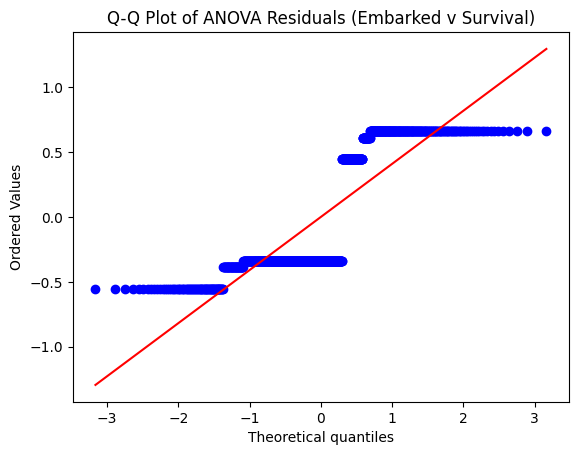

In [29]:
groupC = df_train[(df_train['Embarked_Q'] == 0) & (df_train['Embarked_S'] == 0)]['Survived']
groupQ = df_train[(df_train['Embarked_Q'] == 1) & (df_train['Embarked_S'] == 0)]['Survived']
groupS = df_train[(df_train['Embarked_Q'] == 0) & (df_train['Embarked_S'] == 1)]['Survived']

residuals = np.concatenate([
    groupC - np.mean(groupC),
    groupQ - np.mean(groupQ),
    groupS - np.mean(groupS)
])


stat, p_shapiro = stats.shapiro(residuals)
print("Shapiro-Wilk test for normality of residuals")
print("Test statistic:", stat)
print("p-value:", p_shapiro)
print()

f_stat, p_value = stats.f_oneway(groupC, groupQ, groupS)
print('Embarked v Survival ANOVA')
print(f"F-statistic: {f_stat:.3f}\nP-value: {p_value:.4f}")
print()

stat, p_levene = stats.levene(groupC, groupQ, groupS)
print("Levene’s test")
print(f"Statistic: {stat:.3f}\nP-value: {p_levene:.4f}")

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of ANOVA Residuals (Embarked v Survival)")
plt.show()




### ANOVA: Embarked vs Survival

**Shapiro-Wilk test for normality of residuals**  
- Test statistic: 0.723  
- p-value: 5.68 × 10⁻³⁶  

**Interpretation:** Residuals are **not normally distributed** (p < 0.05).  

**One-way ANOVA**  
- F-statistic: 13.327  
- p-value: 0.0000  

**Interpretation:** The mean survival rate **differs significantly across Embarked groups**. H0 is rejected.  

**Levene’s test for equal variances**  
- Statistic: 3.462  
- p-value: 0.0318  

**Interpretation:** Variances across Embarked groups are **not equal** (p < 0.05).  

**Conclusion:** Both ANOVA assumptions (normality of residuals and homogeneity of variance) are violated.  
- Recommended alternatives: **Welch’s ANOVA** (handles unequal variances) or **Kruskal-Wallis H test** (non-parametric).

In [30]:
group_labels = df_train['Embarked_Q'] + 2 * df_train['Embarked_S']  
tukey_embarked = pairwise_tukeyhsd(endog=df_train['Survived'], groups=group_labels, alpha=0.05)
print(tukey_embarked)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   -0.164 0.0353  -0.319 -0.0089   True
     0      2  -0.2146    0.0 -0.3122  -0.117   True
     1      2  -0.0506 0.6566 -0.1865  0.0853  False
----------------------------------------------------


### Embarked vs Survival Analysis

**Hypotheses:**
- H0: The mean survival rate is the same across all Embarked groups (C, Q, S).  
- H1: At least one Embarked group has a different mean survival rate.

**Shapiro-Wilk test for normality of residuals:**
- Test statistic: 0.723  
- p-value: 5.68e-36  
> Interpretation: Residuals are not normally distributed (p < 0.05).

**ANOVA (Embarked vs Survived):**
- F-statistic: 13.327  
- P-value: 0.0000  
> Interpretation: There is a significant difference in survival rates between Embarked groups.

**Levene’s test for homogeneity of variance:**
- Statistic: 3.462  
- P-value: 0.0318  
> Interpretation: Variances are unequal (p < 0.05), so ANOVA assumptions are violated.

**Tukey HSD post-hoc test:**

| Group1 | Group2 | Mean Diff | p-adj  | Reject H0 |
|--------|--------|-----------|--------|------------|
| 0 (C)  | 1 (Q)  | -0.164    | 0.0353 | True       |
| 0 (C)  | 2 (S)  | -0.2146   | 0.0000 | True       |
| 1 (Q)  | 2 (S)  | -0.0506   | 0.6566 | False      |

> Interpretation: Passengers who embarked at C have significantly higher survival than Q and S. No significant difference between Q and S.  

**Conclusion / Recommendations:**
- Residuals are not normal and variances are unequal → consider using non-parametric alternatives like **Kruskal-Wallis test** for more robust inference.
- Tukey test shows that embarkation location (C vs Q/S) significantly affects survival probability.

In [31]:
contingency = pd.crosstab(df_train['Embarked_Q'] + 2*df_train['Embarked_S'], df_train['Fare_scaled'])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
n = contingency.sum().sum()
r, k = contingency.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Embarked v Survival Chi-square Test")    
print("p-value:", p)
print("Cramér’s V:", cramers_v)


Embarked v Survival Chi-square Test
p-value: 5.730081315003678e-121
Cramér’s V: 0.9557507713548217
